# IND320 Part 3 — Weather data, outliers and time-series analysis

This notebook continues Parts 1 and 2. It adds weather data from **Open-Meteo** (ERA5 reanalysis) for the same
areas as NVE's reservoir statistics, and analyses the data:

1. **Areas:** polygons for the price areas (EL) and NVE regions (VASS) from NVE's map services, with 1000 random
   locations per area.
2. **Weather download:** a function that downloads hourly ERA5 data for an area and a time interval.
3. **Outliers (SPC):** precipitation with seasonally adjusted variations from a Discrete Cosine Transform.
4. **Anomalies (LOF):** temperature with the Local Outlier Factor.
5. **STL decomposition** and 6. **spectrogram** of the reservoir fill level.

## Project links

- Public GitHub repository: https://github.com/yaksh-git/ind320-dashboard-basics-yaksh-git
  (Part 3 is developed on the branch `ind320-part3` and merged into `main` after peer review 2 and feedback 2)
- Streamlit app: https://ind320-dashboard-basics-yaksh-git.streamlit.app/
- Screencast (Part 3): **TODO – add the link before submission**
- The AI-usage statement and the work log are in sections 7 and 8 at the end.

## 1. Setup

The notebook lives in `notebooks/` and uses the project's Python 3.12 environment (`notebooks/requirements.txt`).
Paths are resolved from the repository root. Part 3 needs no passwords: NVE's map services, NVE's reservoir API
and Open-Meteo are all open.

In [1]:
# Standard library
import io
import os
from pathlib import Path

# The repository root holds app.py; Jupyter usually starts in the notebook's own folder (notebooks/).
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

# Matplotlib needs a writable cache folder; set it before Matplotlib is imported (as in Parts 1-2).
mpl_cache = ROOT / '.matplotlib'
mpl_cache.mkdir(exist_ok=True)
os.environ['MPLCONFIGDIR'] = str(mpl_cache.resolve())

# Third-party packages
import geopandas as gpd                       # polygons and random points
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from scipy.fft import dct, idct               # Discrete Cosine Transform (SPC section)
from scipy.signal import spectrogram          # spectrogram section
from sklearn.neighbors import LocalOutlierFactor
from statsmodels.tsa.seasonal import STL      # Seasonal-Trend decomposition using LOESS

sns.set_theme(style='whitegrid', context='notebook', palette='deep')

# Small data files the app also uses (tracked in Git), and a cache for large downloads (Git-ignored).
REGION_DIR = ROOT / 'data' / 'regions'
REGION_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR = ROOT / 'data' / 'cache'
CACHE_DIR.mkdir(parents=True, exist_ok=True)
print('pandas', pd.__version__, '| geopandas', gpd.__version__)

pandas 2.3.3 | geopandas 1.2.0


## 2. Areas and random locations

### 2.1 Polygons from NVE

[atlas.nve.no](https://atlas.nve.no) shows two layers that match the Magasinstatistikk areas. Both are published by
NVE's open map service (the same data the Atlas shows), so they can be downloaded directly as GeoJSON:

| Layer in NVE Atlas | Service | Field | Matches |
|---|---|---|---|
| *Budområder* | `Nettomraader/MapServer/0` | `budomr` = NO 1 … NO 5 | EL 1–5 |
| *NVE_Region* | `Mapservices/Administrasjon2/MapServer/0` | `REGION` = RS, RØ, RV, RM, RN | VASS 1–3 |

As the assignment notes, the VASS regions are split in NVE's region layer: **east = RS + RØ** (VASS 1),
VASS 2 = RV, and **north = RM + RN** (VASS 3). The reservoir capacities agree: VASS 3 (28.2 TWh) is close to the
price areas for Midt- and Nord-Norge together (8.9 + 21.1 TWh). Norway as a whole (NO 0) is the union of the price areas.

In [2]:
# Download one layer of NVE's open map service as GeoJSON in longitude/latitude (EPSG:4326).
NVE_GIS = 'https://kart.nve.no/enterprise/rest/services'


def nve_layer(path, fields):
    """Return all features of one NVE map-service layer as a GeoDataFrame."""
    params = {'where': '1=1', 'outFields': fields, 'outSR': 4326, 'f': 'geojson'}
    response = requests.get(f'{NVE_GIS}/{path}/query', params=params, timeout=120)
    response.raise_for_status()  # stop with a clear error on HTTP 4xx/5xx
    return gpd.read_file(io.BytesIO(response.content))


price_areas = nve_layer('Nettomraader/MapServer/0', 'budomr')
nve_regions = nve_layer('Mapservices/Administrasjon2/MapServer/0', 'REGION,REGIONNAVN')
display(price_areas.drop(columns='geometry'), nve_regions.drop(columns='geometry'))

,budomr
0,NO 1
1,NO 2
2,NO 3
3,NO 4
4,NO 5


,REGION,REGIONNAVN
0,RV,Region Vest
1,RM,Region Midt-Norge
2,RN,Region Nord
3,RØ,Region Øst
4,RS,Region Sør


### 2.2 Keep only land

Both layers include the sea out to the territorial border: together they cover about 470,000 km², while mainland
Norway is about 324,000 km². Random locations at sea would give weather over the ocean, so the areas are clipped
to land. NVE's `Norge_N5000` layer describes the whole country by land-cover type; everything except *Havflate*
(sea surface) is land (forest, open land, lakes, glaciers, …).

In [3]:
# Land mask: every polygon of Norge_N5000 that is not sea, merged into one shape (in metres, EPSG:25833).
norway = nve_layer('Mapservices/Administrasjon2/MapServer/11', 'OBJTYPE')
land = norway.loc[norway['OBJTYPE'] != 'Havflate'].to_crs(25833).union_all()

# One row per Magasinstatistikk area: EL 1-5, VASS 1-3 (from the NVE regions) and NO 0 (all of Norway).
price_m, regions_m = price_areas.to_crs(25833), nve_regions.to_crs(25833)
rows = [('EL', int(code[-1]), code, shape) for code, shape in zip(price_m['budomr'], price_m.geometry)]
VASS_REGIONS = {1: ['RS', 'RØ'], 2: ['RV'], 3: ['RM', 'RN']}
for number, codes in VASS_REGIONS.items():
    rows.append(('VASS', number, f'VASS{number}', regions_m.loc[regions_m['REGION'].isin(codes)].union_all()))
rows.append(('NO', 0, 'Norge', price_m.union_all()))

areas = gpd.GeoDataFrame(rows, columns=['area_type', 'area_number', 'name', 'geometry'], crs=25833)
areas['geometry'] = areas.intersection(land)          # remove the sea
areas['land_km2'] = (areas.area / 1e6).round(0)        # metres² -> km²
areas.drop(columns='geometry')

,area_type,area_number,name,land_km2
0,EL,1,NO 1,59237.0
1,EL,2,NO 2,47845.0
2,EL,3,NO 3,65512.0
3,EL,4,NO 4,116114.0
4,EL,5,NO 5,27603.0
5,VASS,1,VASS1,119834.0
6,VASS,2,VASS2,45963.0
7,VASS,3,VASS3,150514.0
8,NO,0,Norge,316310.0


### 2.3 1000 random locations per area

`sample_points` draws uniformly distributed random points inside each polygon. A fixed seed (`rng=320`) makes the
sample reproducible. The points are saved to `data/regions/sample_points.csv`, which the Streamlit app uses to
download weather for the area chosen in its selector. Simplified polygons are saved for maps.

In [4]:
# 1000 random points inside each land polygon, converted to longitude/latitude.
samples = []
for area in areas.itertuples():
    points = (gpd.GeoSeries([area.geometry], crs=25833)
              .sample_points(1000, rng=320).explode(index_parts=False).to_crs(4326))
    samples.append(pd.DataFrame({'area_type': area.area_type, 'area_number': area.area_number,
                                 'lon': points.x.round(4), 'lat': points.y.round(4)}))
sample_points = pd.concat(samples, ignore_index=True)
sample_points.to_csv(REGION_DIR / 'sample_points.csv', index=False)

# Simplified polygons (500 m tolerance) are small enough for the app and for plotting.
(areas.assign(geometry=areas.simplify(500)).to_crs(4326)
 .to_file(REGION_DIR / 'areas.geojson', driver='GeoJSON'))
print(sample_points.groupby(['area_type', 'area_number']).size().rename('points').to_dict())

{('EL', 1): 1000, ('EL', 2): 1000, ('EL', 3): 1000, ('EL', 4): 1000, ('EL', 5): 1000, ('NO', 0): 1000, ('VASS', 1): 1000, ('VASS', 2): 1000, ('VASS', 3): 1000}


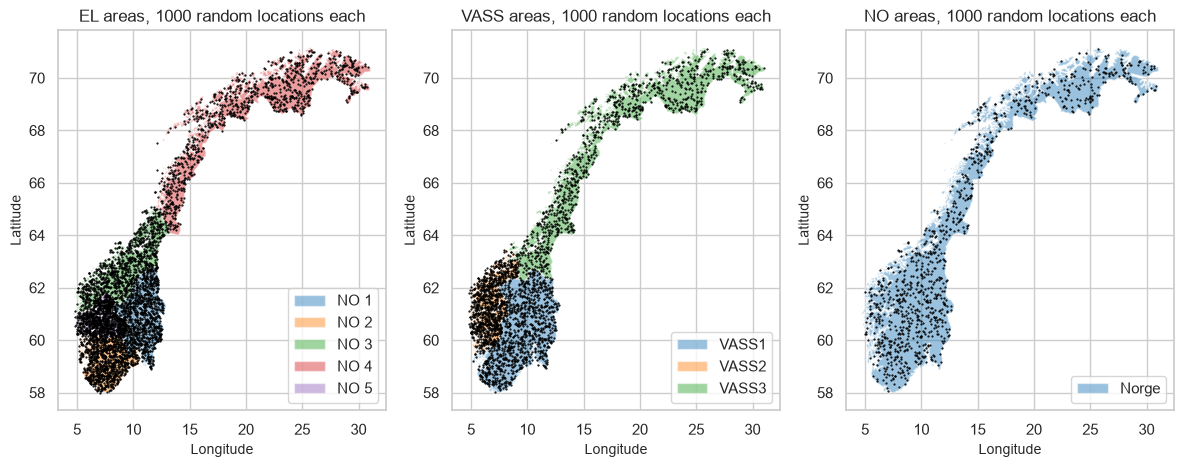

In [5]:
# Map: the areas of each type with their random locations.
fig, axes = plt.subplots(1, 3, figsize=(12, 6))
for ax, area_type in zip(axes, ['EL', 'VASS', 'NO']):
    areas.loc[areas['area_type'] == area_type].to_crs(4326).plot(ax=ax, column='name', alpha=0.45,
                                                                 legend=True, legend_kwds={'loc': 'lower right'})
    pts = sample_points.loc[sample_points['area_type'] == area_type]
    ax.scatter(pts['lon'], pts['lat'], s=0.3, color='black')
    ax.set(title=f'{area_type} areas, 1000 random locations each', xlabel='Longitude', ylabel='Latitude')
fig.tight_layout(); plt.show()

## 3. Weather data from Open-Meteo (ERA5)

The [Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api) returns hourly reanalysis data.
`models=era5` selects ERA5 (0.25° grid, about 28 × 15 km in Norway). Times are returned in UTC.

**How many locations?** The free API counts about 5 *calls* for one year of hourly data with a few variables at one
location, and allows 10,000 calls per day. All 1000 locations of an area would use most of a day's quota, so the
function takes a random subset (`n_locations`, default 20) of the area's 1000 locations. Locations in the same ERA5
grid cell would return identical values, so they are merged first. The area value per hour is the **mean over the
locations**, which the following sections call the average precipitation and temperature. With `n_locations=1` the
function downloads a single location.

In [6]:
# Hourly variables: precipitation and temperature are required; rain, snowfall and wind are useful context.
ARCHIVE_URL = 'https://archive-api.open-meteo.com/v1/archive'
HOURLY = ['temperature_2m', 'precipitation', 'rain', 'snowfall', 'wind_speed_10m']
AREA_KEYS = {**{f'NO{n}': ('EL', n) for n in range(1, 6)},
             **{f'VASS{n}': ('VASS', n) for n in range(1, 4)}, 'NORWAY': ('NO', 0)}


def area_locations(area, n_locations=20, seed=320):
    """Random subset of the area's 1000 sampled locations, one per ERA5 grid cell (0.25°)."""
    area_type, number = AREA_KEYS[area]
    points = sample_points.loc[(sample_points['area_type'] == area_type) & (sample_points['area_number'] == number)]
    # Round to the ERA5 grid so that two points in the same cell are downloaded only once.
    cells = points.assign(lat=(points['lat'] / 0.25).round() * 0.25, lon=(points['lon'] / 0.25).round() * 0.25)
    cells = cells.drop_duplicates(['lat', 'lon'])
    return cells.sample(min(n_locations, len(cells)), random_state=seed)[['lat', 'lon']]


def download_weather(area, start, end, n_locations=20, variables=HOURLY):
    """Download hourly ERA5 data for an area (e.g. 'NO3') between two dates (inclusive).

    Returns (per_location, area_mean): one row per location and hour, and the mean over locations per hour.
    """
    locations = area_locations(area, n_locations)
    params = {'latitude': ','.join(map(str, locations['lat'])), 'longitude': ','.join(map(str, locations['lon'])),
              'start_date': start, 'end_date': end, 'hourly': ','.join(variables), 'models': 'era5'}
    response = requests.get(ARCHIVE_URL, params=params, timeout=300)
    response.raise_for_status()
    answer = response.json()
    answer = answer if isinstance(answer, list) else [answer]  # one location -> one object, several -> a list
    per_location = pd.concat(
        [pd.DataFrame(item['hourly']).assign(location=i, lat=item['latitude'], lon=item['longitude'])
         for i, item in enumerate(answer)], ignore_index=True)
    per_location['time'] = pd.to_datetime(per_location['time'], format='%Y-%m-%dT%H:%M', utc=True)
    area_mean = per_location.groupby('time')[list(variables)].mean()
    return per_location, area_mean


# Apply the function to NO3 for 2024 (cached locally, so re-runs do not download again).
cache_file = CACHE_DIR / 'weather_NO3_2024.parquet'
if cache_file.exists():
    weather_locations = pd.read_parquet(cache_file)
    weather = weather_locations.groupby('time')[HOURLY].mean()
    print(f'Loaded {len(weather_locations):,} cached rows')
else:
    weather_locations, weather = download_weather('NO3', '2024-01-01', '2024-12-31')
    weather_locations.to_parquet(cache_file, index=False)
    print(f'Downloaded {len(weather_locations):,} rows')
print(f"{weather_locations['location'].nunique()} locations, {len(weather):,} hours "
      f"({weather.index.min():%Y-%m-%d} to {weather.index.max():%Y-%m-%d}, UTC)")
weather.describe().round(2)

Loaded 175,680 cached rows
20 locations, 8,784 hours (2024-01-01 to 2024-12-31, UTC)


,temperature_2m,precipitation,rain,snowfall,wind_speed_10m
count,8784.00,8784.00,8784.00,8784.00,8784.00
mean,5.29,0.22,0.18,0.02,10.96
std,7.31,0.30,0.27,0.06,4.38
min,-14.66,0.00,0.00,0.00,2.64
25%,0.52,0.01,0.00,0.00,7.75
50%,4.85,0.10,0.07,0.00,10.04
75%,10.82,0.31,0.25,0.01,13.35
max,24.80,3.16,2.51,0.77,35.89


## 4. Outliers in precipitation (SPC with DCT)

**Idea.** Precipitation has a slow seasonal pattern and fast variations. A **Discrete Cosine Transform (DCT)**
writes the series as a sum of cosines of increasing frequency. Setting the low-frequency coefficients to zero and
transforming back is a **high-pass filter**: what remains are the *seasonally adjusted variations* (SATV). The
removed slow part is the seasonal level.

**Statistical Process Control.** From the SATV of the whole year, robust statistics give the centre (median) and
spread (MAD × 1.4826, which equals the standard deviation for normal data but is not pulled by extreme values). An
hour is an **outlier** when its SATV lies more than `n_sd` robust standard deviations from the median. The plot shows
the precipitation with the control limits *seasonal level + median ± n_sd · sd*; the SATV itself is not plotted.

**Parameters.** `cutoff_per_year` is the frequency cut-off: variations slower than this many cycles per year count
as seasonal (default 12, i.e. about one month). `n_sd` is the number of robust standard deviations (default 3).

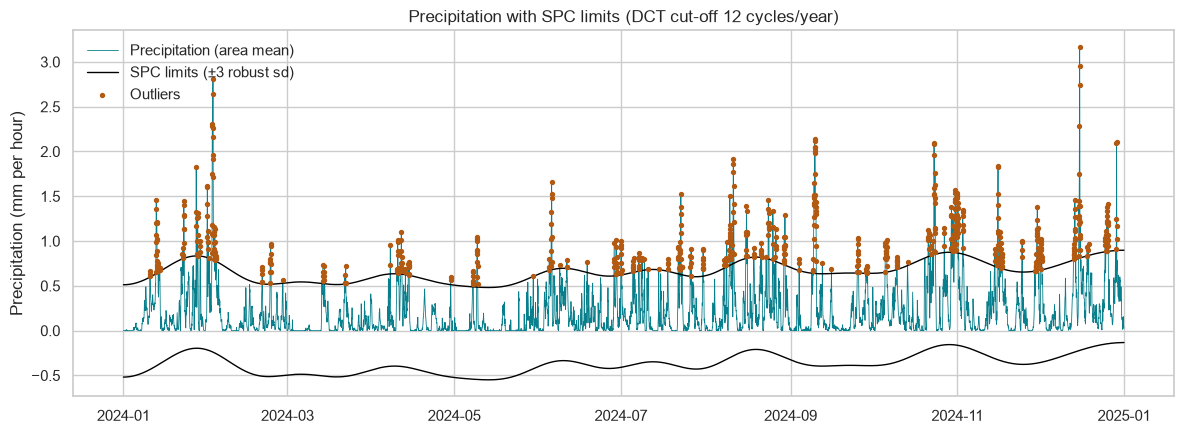

{'hours': 8784, 'outliers': 649, 'share': 0.07388433515482695, 'robust_sd_mm': 0.17178224454992508, 'dct_coefficients_removed': 24}


,precipitation_mm,satv
time,,
2024-12-15 18:00:00+00:00,3.16,2.80
2024-12-15 17:00:00+00:00,2.96,2.59
2024-02-02 18:00:00+00:00,2.81,2.46
2024-12-15 19:00:00+00:00,2.74,2.38
2024-02-02 17:00:00+00:00,2.64,2.30


n_sd=5 gives 187 outliers (vs 649 with n_sd=3)


In [7]:
# SPC function: DCT high-pass filter, robust control limits and a plot with coloured outliers.
def spc_precipitation(series, cutoff_per_year=12, n_sd=3.0):
    """SPC outliers of an hourly series using DCT high-pass filtering; returns (figure, outlier summary)."""
    values = series.to_numpy()
    # total_seconds() avoids a NumPy 2 'generic timedelta' warning seen in Part 2.
    years = (series.index[-1] - series.index[0]).total_seconds() / (365.25 * 24 * 3600)
    # DCT coefficient k represents k/2 cycles over the whole series, so cutoff_per_year maps to k = 2 * cutoff * years.
    k = int(round(2 * cutoff_per_year * years))
    coefficients = dct(values, norm='ortho')
    low = coefficients.copy()
    low[k:] = 0                                        # keep only the slow (seasonal) part ...
    seasonal = idct(low, norm='ortho')
    satv = values - seasonal                           # ... and the rest is the SATV (high-pass)
    centre = np.median(satv)
    sd = 1.4826 * np.median(np.abs(satv - centre))     # robust standard deviation from the MAD
    upper, lower = seasonal + centre + n_sd * sd, seasonal + centre - n_sd * sd
    is_outlier = np.abs(satv - centre) > n_sd * sd

    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.plot(series.index, values, color='#087F8C', linewidth=0.6, label='Precipitation (area mean)')
    ax.plot(series.index, upper, color='black', linewidth=1, label=f'SPC limits (±{n_sd:g} robust sd)')
    ax.plot(series.index, lower, color='black', linewidth=1)
    ax.scatter(series.index[is_outlier], values[is_outlier], color='#B35A12', s=8, zorder=3, label='Outliers')
    ax.set(title=f'Precipitation with SPC limits (DCT cut-off {cutoff_per_year:g} cycles/year)',
           xlabel='', ylabel='Precipitation (mm per hour)')
    ax.legend(loc='upper left', frameon=False)
    fig.tight_layout()

    outliers = pd.DataFrame({'precipitation_mm': values, 'satv': satv}, index=series.index)[is_outlier]
    summary = {'hours': len(values), 'outliers': int(is_outlier.sum()), 'share': float(is_outlier.mean()),
               'robust_sd_mm': float(sd), 'dct_coefficients_removed': k,
               'largest_outliers': outliers.nlargest(5, 'satv').round(2)}
    return fig, summary


# Test: default parameters, then a stricter limit; more standard deviations must give fewer outliers.
fig, summary = spc_precipitation(weather['precipitation'])
plt.show()
print({key: value for key, value in summary.items() if key != 'largest_outliers'})
display(summary['largest_outliers'])
_, strict = spc_precipitation(weather['precipitation'], n_sd=5)
plt.close('all')
assert strict['outliers'] < summary['outliers']
print(f"n_sd=5 gives {strict['outliers']} outliers (vs {summary['outliers']} with n_sd=3)")

**Findings.** Hourly precipitation is very skewed: most hours have little or no rain, and a few have heavy showers.
The robust spread is therefore small (about 0.17 mm/h), and with 3 robust standard deviations about 7 % of the hours
are flagged; with 5 standard deviations about 2 %. The outliers come in clusters, which are single rain events, for
example the storms on 2 February and 15 December 2024. They are real weather, not data errors: SPC here marks
unusually wet hours relative to the season. The **lower limit is negative**, so it can never be crossed
(precipitation is never below 0 mm); only the upper limit matters for this variable.

## 5. Anomalies in temperature (LOF)

The **Local Outlier Factor** compares the density around each point with the density around its neighbours. A point
in a sparser region than its neighbours gets a high factor. Each hour is described by two standardised features,
its time and its temperature, so a point is anomalous when its temperature is unusual compared with the
**surrounding hours**. `proportion` sets the expected share of anomalies (default 1 %).

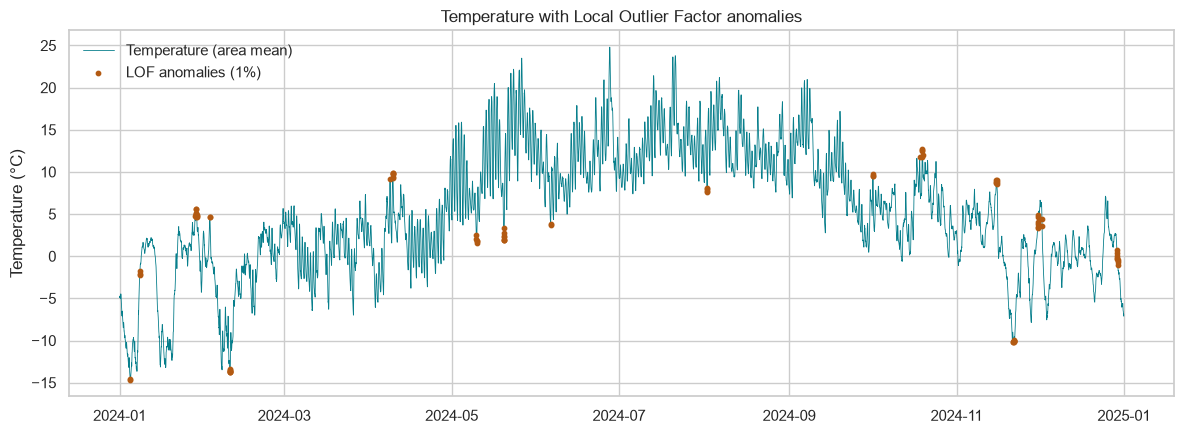

{'hours': 8784, 'anomalies': 88, 'share': 0.010018214936247723, 'mean_temperature_c': 5.291783356102004}


,temperature_c,lof_score
time,,
2024-05-20 03:00:00+00:00,1.90,2.07
2024-05-20 02:00:00+00:00,1.86,2.07
2024-05-20 01:00:00+00:00,1.90,2.06
2024-05-20 00:00:00+00:00,2.26,1.97
2024-11-15 13:00:00+00:00,9.08,1.92


proportion=0.03 gives 264 anomalies (vs 88 with 0.01)


In [8]:
# LOF function: Local Outlier Factor on (time, temperature) and a plot with the anomalies.
def lof_temperature(series, proportion=0.01, n_neighbors=48):
    """Local Outlier Factor anomalies of an hourly temperature series; returns (figure, anomaly summary)."""
    days = (series.index - series.index[0]).total_seconds().to_numpy() / (24 * 3600)
    features = np.column_stack([days, series.to_numpy()])
    features = (features - features.mean(axis=0)) / features.std(axis=0)   # same scale for time and temperature
    lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=proportion)
    is_anomaly = lof.fit_predict(features) == -1                           # -1 = anomaly, 1 = normal

    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.plot(series.index, series, color='#087F8C', linewidth=0.6, label='Temperature (area mean)')
    ax.scatter(series.index[is_anomaly], series[is_anomaly], color='#B35A12', s=10, zorder=3,
               label=f'LOF anomalies ({proportion:.0%})')
    ax.set(title='Temperature with Local Outlier Factor anomalies', xlabel='', ylabel='Temperature (°C)')
    ax.legend(loc='upper left', frameon=False)
    fig.tight_layout()

    anomalies = pd.DataFrame({'temperature_c': series[is_anomaly],
                              'lof_score': -lof.negative_outlier_factor_[is_anomaly]})
    summary = {'hours': len(series), 'anomalies': int(is_anomaly.sum()), 'share': float(is_anomaly.mean()),
               'mean_temperature_c': float(series.mean()),
               'strongest_anomalies': anomalies.nlargest(5, 'lof_score').round(2)}
    return fig, summary


# Test: default 1 %, then 3 %; the number of anomalies must follow the chosen proportion.
fig, summary = lof_temperature(weather['temperature_2m'])
plt.show()
print({key: value for key, value in summary.items() if key != 'strongest_anomalies'})
display(summary['strongest_anomalies'])
_, more = lof_temperature(weather['temperature_2m'], proportion=0.03)
plt.close('all')
assert abs(summary['share'] - 0.01) < 0.002 and abs(more['share'] - 0.03) < 0.002
print(f"proportion=0.03 gives {more['anomalies']} anomalies (vs {summary['anomalies']} with 0.01)")

**Findings.** LOF marks short periods (a few consecutive hours) whose temperature does not fit the hours around
them: for example the coldest hours in early January and February, cold nights around 20 May, and a mild spell in
mid-November. They are not simply the warmest or coldest hours of the year (the summer peaks are not flagged),
because LOF compares each hour with its own neighbourhood in time. Raising `proportion` from 1 % to 3 % triples the
number of anomalies, as the test checks.

## 6. Reservoir fill level: STL and spectrogram

The weekly fill level comes directly from NVE's Magasinstatistikk API, as in Part 2. The default area is the price
area NO3, the same area as the weather data.

In [9]:
# Weekly fill level for one area (date = the Sunday that ends the ISO week, as found in Part 2).
nve = pd.DataFrame(requests.get('https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData',
                                headers={'Accept': 'application/json'}, timeout=60).json())
nve['date'] = pd.to_datetime(nve['dato_Id'], format='%Y-%m-%d')
fill_no3 = (nve.loc[(nve['omrType'] == 'EL') & (nve['omrnr'] == 3)]
            .set_index('date')['fyllingsgrad'].sort_index().asfreq('7D'))   # regular weekly index
print(f'{len(fill_no3)} weeks, {fill_no3.index.min():%Y-%m-%d} to {fill_no3.index.max():%Y-%m-%d}, '
      f'missing weeks: {fill_no3.isna().sum()}')

1661 weeks, 1995-01-08 to 2026-11-01, missing weeks: 0


### 6.1 Seasonal-Trend decomposition using LOESS (STL)

STL splits the series into **trend + seasonal + remainder** with local regression (LOESS). The period is 52 weeks.
`seasonal` is the length of the seasonal smoother (odd, default 13: the yearly pattern may change slowly),
`trend` the length of the trend smoother (odd and longer than the period, default 105 weeks ≈ 2 years), and
`robust=True` reduces the influence of unusual weeks on the trend and season.

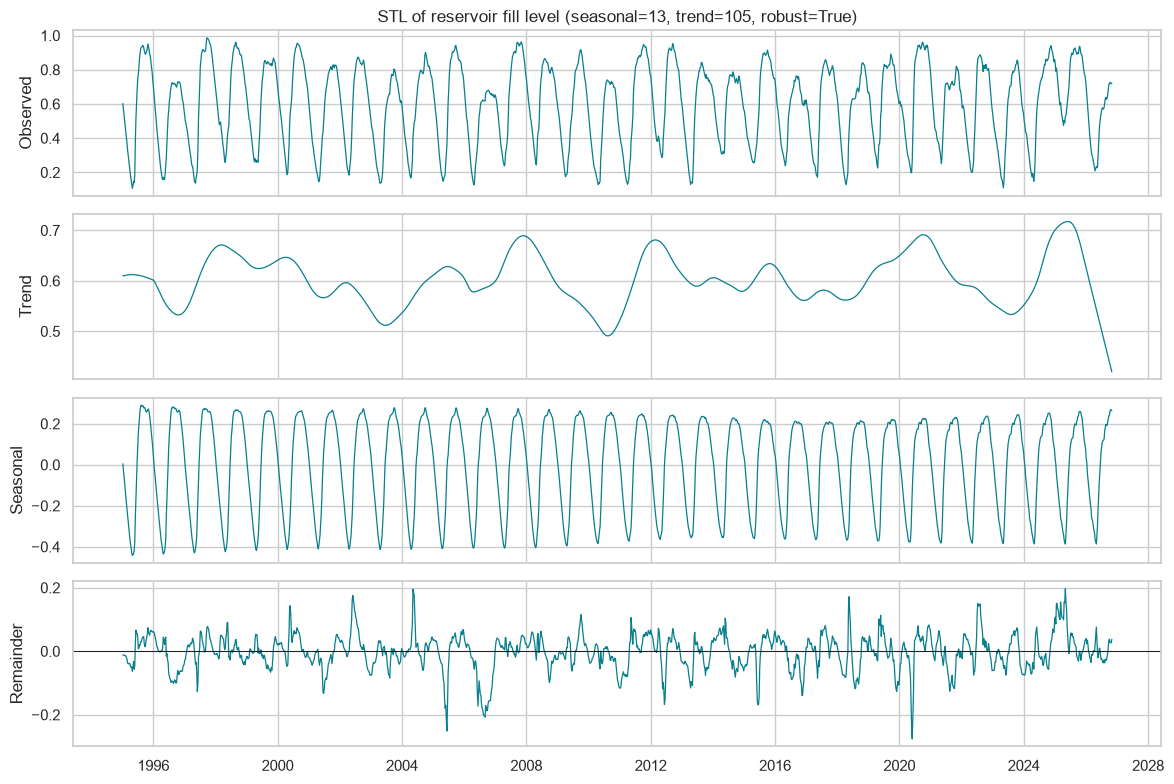

Trend + seasonal + remainder equals the observed series.


In [10]:
# STL function: trend, seasonal and remainder of the weekly fill level.
def stl_fill_level(series, seasonal=13, trend=105, robust=True, period=52):
    """STL decomposition of a weekly series; returns the figure with observed, trend, seasonal and remainder."""
    result = STL(series.interpolate(), period=period, seasonal=seasonal, trend=trend, robust=robust).fit()
    parts = {'Observed': result.observed, 'Trend': result.trend, 'Seasonal': result.seasonal,
             'Remainder': result.resid}
    fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
    for ax, (name, values) in zip(axes, parts.items()):
        ax.plot(values.index, values, color='#087F8C', linewidth=0.9)
        ax.set(ylabel=name)
    axes[-1].axhline(0, color='black', linewidth=0.6)
    axes[0].set_title(f'STL of reservoir fill level (seasonal={seasonal}, trend={trend}, robust={robust})')
    fig.tight_layout()
    return fig


# Test: the default decomposition, and a check that trend + seasonal + remainder rebuild the series.
fig = stl_fill_level(fill_no3)
plt.show()
check = STL(fill_no3.interpolate(), period=52, seasonal=13, trend=105, robust=True).fit()
assert np.allclose(check.trend + check.seasonal + check.resid, fill_no3.interpolate())
print('Trend + seasonal + remainder equals the observed series.')

**Findings.** The seasonal part is the yearly cycle: reservoirs are drawn down in winter and spring and filled by
snow melt in late spring and summer. Its amplitude has become somewhat smaller since about 2010. The trend moves
between about 0.5 and 0.7: low in dry periods (2003, 2010, 2023) and high in wet ones (2007–08, 2012, 2020, 2025).
The sharp drop at the very end is partly an edge effect: LOESS only has data on one side of the last weeks. The
largest negative remainders are in late May and June 2005 and 2020, when the snow melt and filling started later than
usual, and in August 2006, a dry late summer.

### 6.2 Spectrogram

A spectrogram shows how the strength of each frequency changes over time. The series is cut into overlapping windows
and each window is Fourier transformed. With weekly data the sampling frequency is 52 per year, so the frequency
axis is in **cycles per year**. `window_weeks` is the window length (default 104 weeks = 2 years, enough to resolve
a yearly cycle) and `overlap_weeks` the overlap between windows (default 78 weeks = 75 %).

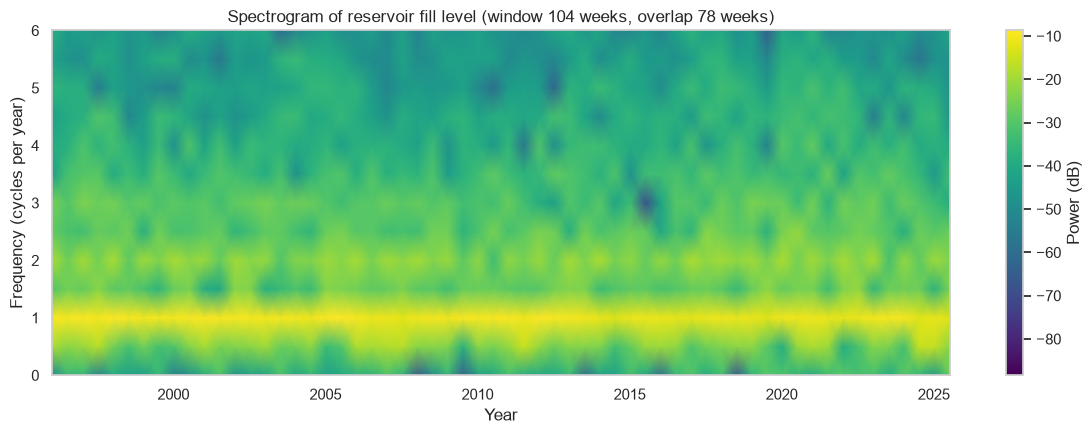

Strongest frequency: 1.0 cycles per year


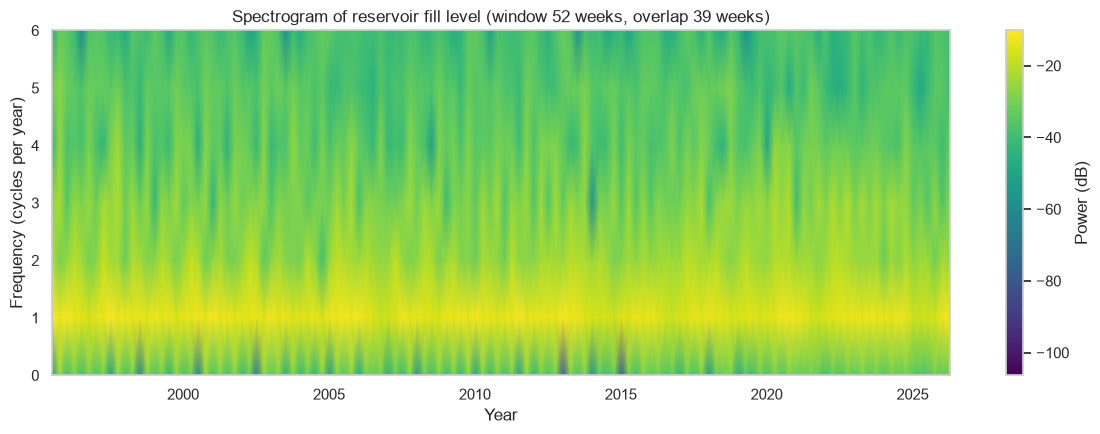

In [11]:
# Spectrogram function: power per frequency (cycles per year) in sliding windows.
def spectrogram_fill_level(series, window_weeks=104, overlap_weeks=78):
    """Spectrogram of a weekly series (frequency in cycles per year); returns the figure."""
    values = series.interpolate().to_numpy()
    freqs, times, power = spectrogram(values - values.mean(), fs=52, nperseg=window_weeks, noverlap=overlap_weeks)
    years = series.index[0].year + series.index[0].dayofyear / 365.25 + times   # window centres in years
    fig, ax = plt.subplots(figsize=(12, 4.5))
    mesh = ax.pcolormesh(years, freqs, 10 * np.log10(power + 1e-12), shading='gouraud', cmap='viridis')
    fig.colorbar(mesh, ax=ax, label='Power (dB)')
    ax.set(title=f'Spectrogram of reservoir fill level (window {window_weeks} weeks, overlap {overlap_weeks} weeks)',
           xlabel='Year', ylabel='Frequency (cycles per year)', ylim=(0, 6))
    fig.tight_layout()
    return fig


# Test: default parameters, and a shorter window (better time resolution, coarser frequencies).
fig = spectrogram_fill_level(fill_no3)
plt.show()
# The strongest frequency, averaged over all windows, must be the yearly cycle (1 cycle per year).
values = fill_no3.interpolate().to_numpy()
freqs, _, power = spectrogram(values - values.mean(), fs=52, nperseg=104, noverlap=78)
assert freqs[power.mean(axis=1).argmax()] == 1.0
print('Strongest frequency:', freqs[power.mean(axis=1).argmax()], 'cycles per year')
fig = spectrogram_fill_level(fill_no3, window_weeks=52, overlap_weeks=39)
plt.show()

**Findings.** The strongest band is at **1 cycle per year** in every window: the yearly fill-and-draw-down cycle
dominates the whole period. Weaker bands at 2 and 3 cycles per year are harmonics, because the cycle is not a pure
sine (filling is faster than drawing down). With a one-year window the time resolution is better, but the
frequency bands become wider.

## 7. AI usage

As in Part 2, I used Claude Code (the Claude desktop app) as my main tool. I started Part 3 on 31 October by giving it the assignment text and saying that peer review 2 and feedback 2 were finished. It read the assignment, the `AGENTS.md` rules from Part 2 and my notes, created the branch `ind320-part3`, and checked the NVE map services, the Open-Meteo documentation and the libraries used (SciPy, scikit-learn, statsmodels and GeoPandas).

Claude drafted the notebook code and text and the two new Streamlit pages. It tested small prototypes of each method before it wrote the notebook. Before it changed the existing app, it described the planned design: a shared area selector, weather downloaded in the background instead of on its own page, and the new page order. I approved the design first. I asked it to explain the methods and the code while it worked, and I checked the results against what I expected. On 4 November I asked it to check every requirement before filming, which found four notebook cells without a leading comment and a spectrogram test without an `assert`.

**Claude also drafted this AI-usage section and the work log in section 8**, based on what we actually did. I read through both and adjusted them before submission. I approved every merge into the main branch myself, and I recorded the screencast myself.

What I learned along the way:

- how NVE's map layers relate to the Magasinstatistikk areas (east = RS + RØ, north = RM + RN), and that the polygons include the sea, so they must be clipped to land before drawing random points;
- that the Discrete Cosine Transform can be used as a high-pass filter, and why the median and the MAD are better than the mean and the standard deviation when there are outliers;
- how the Local Outlier Factor compares the density around a point with that of its neighbours;
- how STL splits a series into trend, season and remainder, and why the trend is less reliable at the ends;
- how to read a spectrogram, and why a window must cover more than one period to resolve a yearly cycle;
- to think about API limits before downloading: 1000 locations for a whole year would use most of Open-Meteo's free daily quota.

## 8. Work log

I started Part 3 on 31 October, after peer review 2 and feedback 2, both of which were positive. I worked on a new branch, so the app on the main branch stayed unchanged until the work was finished.

The first task was to find the areas. The download page in NVE Atlas asks for an e-mail address and returns the files later, so I used the open map services behind atlas.nve.no instead, which return GeoJSON directly. The price areas match EL 1–5. The NVE regions had to be combined: east is RS + RØ and north is RM + RN. The reservoir capacities agreed with this, because VASS 3 (28.2 TWh) is close to NO 3 and NO 4 together. The first areas were far too large, about 470,000 km² in total, because the polygons include the sea out to the territorial border. Random points at sea would give ocean weather, so I clipped the areas to land with NVE's Norway layer, which gave 316,000 km². Then I drew 1000 random points per area with a fixed seed and saved them in the repository, so the app can use them.

For the weather I wrote a function that takes an area and a time interval and downloads hourly ERA5 data from Open-Meteo. Downloading all 1000 locations for a year would use most of the free daily quota, so the function downloads 20 random locations, one per ERA5 grid cell, and averages them. For SPC on precipitation, about 7 % of the hours in NO3 2024 were outliers, and the lower control limit was negative. Hourly precipitation is very skewed, with many dry hours, so the robust spread is small, and only the upper limit matters. With 1 % LOF on temperature, 88 hours were flagged, mostly short cold or mild spells that did not fit the hours around them. STL on the fill level showed the yearly cycle and a trend between about 0.5 and 0.7; the drop at the very end is partly an edge effect. The spectrogram showed that the yearly cycle at 1 cycle per year dominates every window. A NumPy deprecation warning came back from dividing time differences, and I removed it in the same way as in Part 2.

In the app I made the area-type radio shared by pages 2–5 and added a select box for one area on the two new pages. The weather is downloaded when the weather page needs it and is cached, so a separate download page was not needed. The sidebar now groups the pages by data source. Before filming I went through the requirements once more and fixed four notebook cells that did not start with a comment, and added a real test to the spectrogram. The most important lesson was again to compare every result with what I expected, as with the sea in the area polygons.